## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Tự tìm thư mục project chứa dữ liệu gốc,
# không phụ thuộc notebook đang được mở từ thư mục nào.
current_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    folder
    for folder in [current_dir, *current_dir.parents]
    if (folder / "data" / "raw" / "Online Retail.xlsx").exists()
)

RAW_PATH = PROJECT_ROOT / "data" / "raw" / "Online Retail.xlsx"

print("Thư mục đang chạy notebook:", current_dir)
print("Thư mục project:", PROJECT_ROOT)
print("Đường dẫn dữ liệu gốc:", RAW_PATH)
print("Tệp tồn tại:", RAW_PATH.exists())

df_raw = pd.read_excel(RAW_PATH, sheet_name="Online Retail")

print("Kích thước dữ liệu:", df_raw.shape)
display(df_raw.head())
df_raw.info()

Thư mục đang chạy notebook: C:\Users\dell\Documents\GitHub\SGU-ML-High-Value-Customer-Prediction\project\notebooks\05_data_processing\13-11-2026_an_preprocessing
Thư mục project: C:\Users\dell\Documents\GitHub\SGU-ML-High-Value-Customer-Prediction\project
Đường dẫn dữ liệu gốc: C:\Users\dell\Documents\GitHub\SGU-ML-High-Value-Customer-Prediction\project\data\raw\Online Retail.xlsx
Tệp tồn tại: True
Kích thước dữ liệu: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


Dữ liệu được nạp thành công, có 541909 dòng, 8 cột 

## Khảo sát chất lượng dữ liệu thô

In [4]:
print("Missing values:")
display(df_raw.isna().sum().to_frame("missing_count"))

print("Dòng trùng hoàn toàn:", df_raw.duplicated().sum())

print("Hóa đơn hủy (InvoiceNo bắt đầu bằng C):",
      df_raw["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Quantity <= 0:", (df_raw["Quantity"] <= 0).sum())
print("UnitPrice <= 0:", (df_raw["UnitPrice"] <= 0).sum())

print("Số khách hàng có mã:", df_raw["CustomerID"].nunique())
print("Số hóa đơn:", df_raw["InvoiceNo"].nunique())
print("Số quốc gia:", df_raw["Country"].nunique())

Missing values:


,missing_count
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Dòng trùng hoàn toàn: 5268
Hóa đơn hủy (InvoiceNo bắt đầu bằng C): 9288
Quantity <= 0: 10624
UnitPrice <= 0: 2517
Số khách hàng có mã: 4372
Số hóa đơn: 25900
Số quốc gia: 38


In [5]:
display(df_raw[df_raw["CustomerID"].isna()].head())
display(df_raw[df_raw["InvoiceNo"].astype(str).str.startswith("C")].head())
display(df_raw[(df_raw["Quantity"] <= 0) | (df_raw["UnitPrice"] <= 0)].head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


Dữ liệu có giá trị thiếu ở CustomerId, có dòng trùng lặp

# Chia từng fearture

In [6]:
mun_columns = df_raw.columns[df_raw.isnull().any()].tolist()
cat_columns = df_raw.select_dtypes(include="object").columns.tolist()
date_columns = df_raw.select_dtypes(include="datetime").columns.tolist()

C:\Users\dell\AppData\Local\Temp\ipykernel_51144\2788779254.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_columns = df_raw.select_dtypes(include="object").columns.tolist()


In [7]:
df_raw.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


Dữ liệu gồm 541909 giao dịch, thời gian từ 01/12/2010 đên 09/12/2011

CustomerId có 406829 giá trị, có 135080 giao dịch thiếu

Quantity có trung vị là 3, giá trị nhỏ nhất là -80.995 lớn nhất là 80.995, độ lệch chuẩn 218,08, dữ liệu có giao dịch trả huỷ hoặc giá trị ngoại tệ lớn

UnitPrice có trung vị 2,08, trung bình 4,61 nhưng giá trị âm -11.062,06 và cực đại 38.970, Cần kiểm tra các giao dịch có UnitPrice <= 0 và các giá trị bất thường

Trung bình lớn hơn trung vị ở Quantity và UnitPrice, hai biến bị lệch phải và chịu ảnh hưởng bởi một số giao dịch có giá trị rất lớn.

InvoiceDate không bị thiếu, có thể dùng để tính Recency trong mô hình RFM.

Trước khi phân cụm, các đặc trưng RFM có thể cần biến đổi log1p và chuẩn hóa để giảm ảnh hưởng của phân phối lệch và outlier.

## Kiểm tra giá trị khác nhau của các fearture object

In [8]:
print("Giá trị khác nhau của các cột categorical:")
for col in cat_columns:
    print(f"- {col}: {df_raw[col].nunique()}")

Giá trị khác nhau của các cột categorical:
- InvoiceNo: 25900
- StockCode: 4070
- Description: 4223
- Country: 38


## Chuyển đổi datatype cho các biến phân loại

In [9]:
df_raw['StockCode'] = df_raw['StockCode'].astype('category')
df_raw['Description'] = df_raw['Description'].astype('category') 
df_raw['Country'] = df_raw['Country'].astype('category')
df_raw['CustomerID'] = df_raw['CustomerID'].astype('category')
print("\nData types after conversion:")
display(df_raw.dtypes)


Data types after conversion:


InvoiceNo              object
StockCode            category
Description          category
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID           category
Country              category
dtype: object

## Kiểm tra phần trăm missing

In [10]:
def check_missing_values(df):
    missing_values = df.isnull().sum()
    missing_percentage = (missing_values / len(df)) * 100
    missing_df = pd.DataFrame({
        'Missing Values': missing_values,
        'Percentage': missing_percentage
    })
    return missing_df[missing_df['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False)

In [11]:
check_missing_values(df_raw)

,Missing Values,Percentage
CustomerID,135080,24.926694
Description,1454,0.268311


CustomerId thiếu 25%

Với 25% này có nên xoá dữ liệu không?

Description 0.2%, chưa thể nhận xét

## Kiểm tra các biến trùng lặp

In [12]:
duplicate_columns = []

for i, col_1 in enumerate(df_raw.columns):
    for col_2 in df_raw.columns[i + 1:]:
        if df_raw[col_1].equals(df_raw[col_2]):
            duplicate_columns.append((col_1, col_2))

if duplicate_columns:
    print("Các cột trùng hoàn toàn:")
    for col_1, col_2 in duplicate_columns:
        print(f"- {col_1} và {col_2}")
else:
    print("Không có cột nào trùng hoàn toàn.")

Không có cột nào trùng hoàn toàn.


In [13]:
duplicate_rows = df_raw[df_raw.duplicated(keep=False)].sort_values(
    by=list(df_raw.columns)
)

print("Số dòng trùng hoàn toàn:", df_raw.duplicated().sum())
print("Tổng số dòng thuộc nhóm trùng:", len(duplicate_rows))

display(duplicate_rows.head(10))

Số dòng trùng hoàn toàn: 5268
Tổng số dòng thuộc nhóm trùng: 10147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


## Xử lý các dấu chấm, hỏi

In [14]:
unwanted_values = ['?', '!', '$', 'None', 'null', '', '*'] 

# Replace unwanted values with NaN   
for col in df_raw.columns: 
    df_raw.loc[:, col] = df_raw[col].replace(unwanted_values, np.nan)

In [15]:
check_missing_values(df_raw)

,Missing Values,Percentage
CustomerID,135080,24.926694
Description,1501,0.276984


## Handling Missing Values

### 1. Backward Fill (bfill) and Forward Fill (ffill) methods

In [16]:
df_fill = df_raw.copy()

df_fill["Description"] = df_fill["Description"].ffill().bfill()
df_fill["CustomerID"] = df_fill["CustomerID"].ffill().bfill()

print(df_fill[["Description", "CustomerID"]].isna().sum())

Description    0
CustomerID     0
dtype: int64


### 2. The Mode Method

In [17]:
df_mode = df_raw.copy()

# Impute missing values in 'Description' column with the mode
mode_description = df_mode['Description'].mode()[0]
df_mode['Description'].fillna(mode_description, inplace=True)

# Impute missing values in 'CustomerID' column with the mode
mode_customer_id = df_mode['CustomerID'].mode()[0]
df_mode['CustomerID'].fillna(mode_customer_id, inplace=True)

# Verify the imputation
print(df_mode[['Description', 'CustomerID']].isnull().sum())

Description      1501
CustomerID     135080
dtype: int64


C:\Users\dell\AppData\Local\Temp\ipykernel_51144\1419057700.py:5: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df_mode['Description'].fillna(mode_description, inplace=True)
C:\Users\dell\AppData\Local\Temp\ipykernel_51144\1419057700.py:9: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through cha

* Kết hợp cả hai phương pháp

* Cơ sở lý luận cho việc kết hợp phương pháp điền bằng yếu vị (Mode) và điền tiến/lùi (Forward/Backward Fill)

* Dự án này tập trung vào việc tìm hiểu sâu về hành vi khách hàng, hiệu suất bán hàng và xu hướng sản phẩm. Mặc dù các phương pháp xử lý giá trị thiếu (imputation) có thể ảnh hưởng đến chất lượng dữ liệu, hai cột 'Description' (Mô tả) và 'CustomerID' (Mã khách hàng) có mức độ quan trọng khác nhau đối với mục tiêu phân tích chính của chúng tôi. Để đảm bảo tính rõ ràng và độ tin cậy trong quá trình tiền xử lý dữ liệu, cách tiếp cận sau đây đã được áp dụng:

* Điền bằng yếu vị (Mode Imputation) cho cột 'Description': Do cột 'Description' có ít giá trị bị thiếu hơn và ít quan trọng hơn đối với phân tích chính, phương pháp điền bằng giá trị xuất hiện nhiều nhất (mode) đã được sử dụng. Cách này đảm bảo tính nhất quán bằng cách thay thế các giá trị thiếu bằng danh mục phổ biến nhất.

* Điền tiến/lùi (Forward/Backward Fill) cho cột 'CustomerID': Cột 'CustomerID' có số lượng giá trị bị thiếu đáng kể. Việc sử dụng phương pháp điền tiến (lấy giá trị trước đó) và điền lùi (lấy giá trị kế tiếp) giúp tránh tình trạng một mã khách hàng duy nhất bị lặp lại quá mức, đồng thời duy trì tính liên quan theo thời gian và độ chính xác về mặt ngữ cảnh của dữ liệu.

* Bằng cách ghi chép và so sánh các phương pháp này, mục tiêu đặt ra là cung cấp một cái nhìn toàn diện về các kỹ thuật xử lý giá trị thiếu đã được sử dụng, từ đó hỗ trợ việc ra quyết định tốt hơn và đảm bảo tính minh bạch trong quá trình phân tích.

### 3. Combination of Both Methods

In [18]:
df_combined = df_raw.copy()

# Điền Description thiếu bằng giá trị xuất hiện nhiều nhất
mode_description = df_combined["Description"].mode()[0]
df_combined["Description"] = df_combined["Description"].fillna(mode_description)

df_combined["CustomerID"] = df_combined["CustomerID"].ffill().bfill()

print(df_combined[["Description", "CustomerID"]].isnull().sum())

Description    0
CustomerID     0
dtype: int64


In [19]:
df_combined = df_combined.drop_duplicates()

Sau khi xử lý, các giá trị thiếu ở Description và CustomerID đều bằng 0. Tuy nhiên, việc điền CustomerID bằng ffill() và bfill() có thể gán nhầm giao dịch cho khách hàng khác, nên không sử dụng dữ liệu này để tính RFM hoặc phân cụm. Việc loại bỏ dòng trùng lặp được thực hiện bằng drop_duplicates().

## Xử lý outlier

In [20]:
df_filter_out = df_combined.copy()
df_filter_out = df_filter_out[df_filter_out['Quantity'] > 0]
df_filter_out = df_filter_out[df_filter_out['UnitPrice'] > 0]

In [21]:
print(f'Trước khi lọc: {df_combined.shape}')
print(f'Sau khi lọc: {df_filter_out.shape}')

Trước khi lọc: (536641, 8)
Sau khi lọc: (524878, 8)


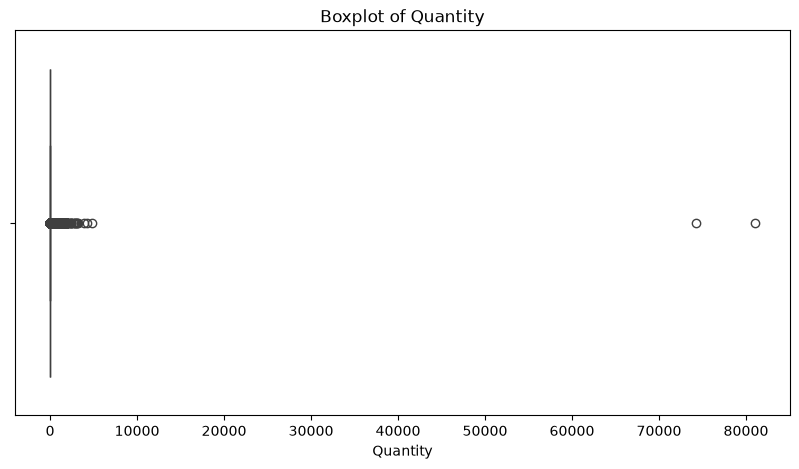

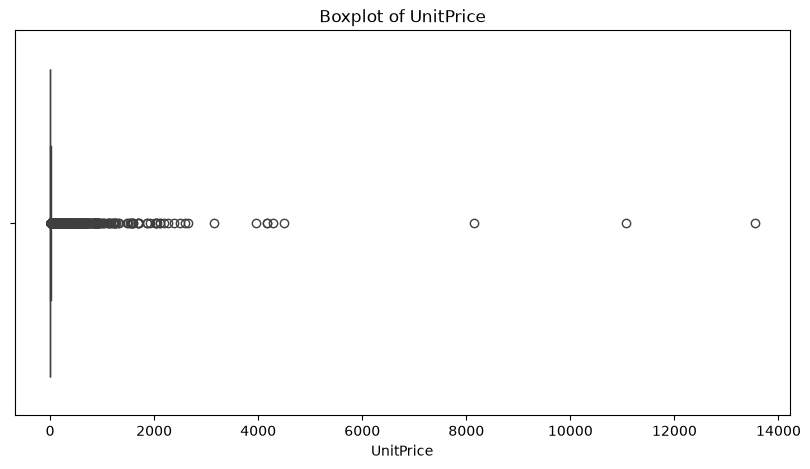

In [25]:
num_columns = df_filter_out.select_dtypes(include=[np.number]).columns.tolist()
for col in num_columns:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=df_filter_out[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

## Xử lý outlier bằng zscore

In [28]:
from pathlib import Path

# Đường dẫn thư mục data cạnh notebook preprocessing
OUTPUT_DIR = (
    PROJECT_ROOT
    / "notebooks"
    / "05_data_processing"
    / "13-11-2026_an_preprocessing"
    / "data"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Tính Z-score cho Quantity và UnitPrice
df_zscore = df_filter_out.copy()

for col in ["Quantity", "UnitPrice"]:
    mean = df_zscore[col].mean()
    std = df_zscore[col].std(ddof=0)

    df_zscore[f"{col}_zscore"] = (df_zscore[col] - mean) / std

# Giữ các giao dịch có Z-score nằm trong [-3, 3] ở cả hai biến
outlier_mask = (
    (df_zscore["Quantity_zscore"].abs() > 3)
    | (df_zscore["UnitPrice_zscore"].abs() > 3)
)

print("Số dòng trước khi loại outlier:", len(df_zscore))
print("Số outlier bị loại:", outlier_mask.sum())

df_clean = df_zscore.loc[~outlier_mask].drop(
    columns=["Quantity_zscore", "UnitPrice_zscore"]
)

print("Số dòng sau khi loại outlier:", len(df_clean))

# Lưu dữ liệu đã làm sạch
OUTPUT_PATH = OUTPUT_DIR / "online_retail_clean_zscore.csv"
df_clean.to_csv(OUTPUT_PATH, index=False)

print("Đã lưu tại:", OUTPUT_PATH)

Số dòng trước khi loại outlier: 524878
Số outlier bị loại: 1301
Số dòng sau khi loại outlier: 523577
Đã lưu tại: C:\Users\dell\Documents\GitHub\SGU-ML-High-Value-Customer-Prediction\project\notebooks\05_data_processing\13-11-2026_an_preprocessing\data\online_retail_clean_zscore.csv
